Audio engineering basics 

In [1]:
from pydub import AudioSegment

In [2]:
audio=AudioSegment.from_file("song.mp3")

In [3]:
print("Duration (ms):", len(audio))
print("Channels:", audio.channels)
print("Frame Rate:", audio.frame_rate)
print("Sample Width (bytes):", audio.sample_width)
print("dBFS (average loudness):", audio.dBFS)

Duration (ms): 238330
Channels: 2
Frame Rate: 44100
Sample Width (bytes): 2
dBFS (average loudness): -8.99217801279998


In [4]:
first_5_sec = audio[:5000]
next_5_sec = audio[5000:10000]

print("First 5 sec duration:", len(first_5_sec))
print("Next 5 sec duration:", len(next_5_sec))

First 5 sec duration: 5000
Next 5 sec duration: 5000


In [5]:
fade_in_clip = audio[:5000].fade_in(3000)
fade_out_clip = audio[:5000].fade_out(3000)

print("Fade-in clip:", fade_in_clip)
print("Fade-out clip:", fade_out_clip)

Fade-in clip: <pydub.audio_segment.AudioSegment object at 0x000001F5A3D38C80>
Fade-out clip: <pydub.audio_segment.AudioSegment object at 0x000001F5A2AF8F50>


In [6]:
combined=first_5_sec+next_5_sec
print("length",len(combined))

length 10000


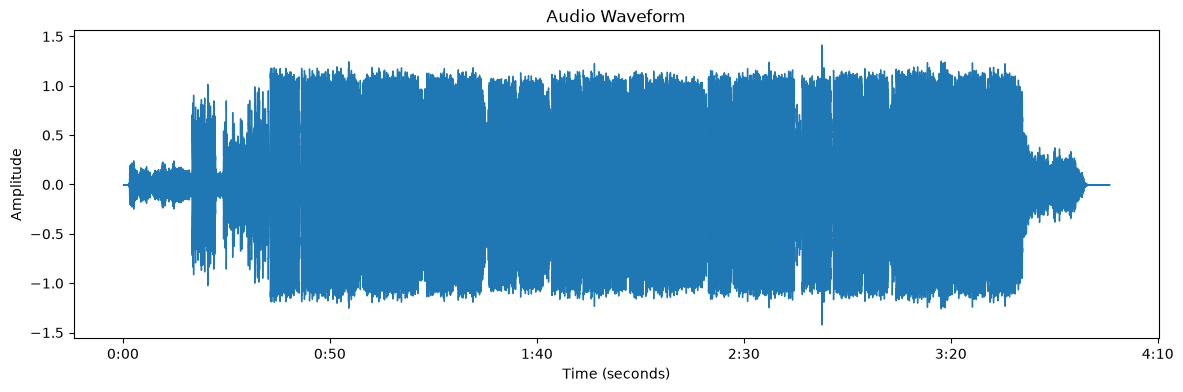

In [7]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

y, sr = librosa.load("song.mp3", sr=None)

plt.figure(figsize=(14, 4))
librosa.display.waveshow(y, sr=sr)
plt.title("Audio Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.show()


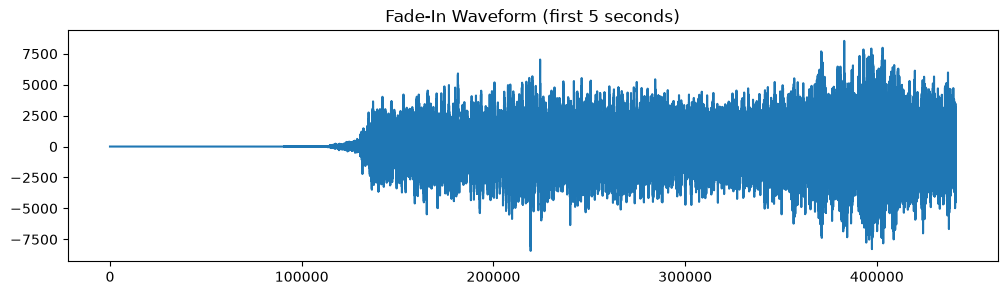

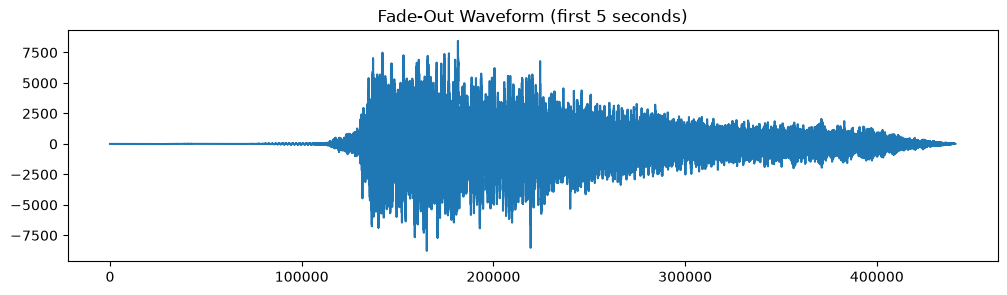

In [8]:
fade_in_audio = fade_in_clip.get_array_of_samples()
fade_out_audio = fade_out_clip.get_array_of_samples()

plt.figure(figsize=(12, 3))
plt.plot(fade_in_audio)
plt.title("Fade-In Waveform (first 5 seconds)")
plt.show()

plt.figure(figsize=(12, 3))
plt.plot(fade_out_audio)
plt.title("Fade-Out Waveform (first 5 seconds)")
plt.show()


In [9]:
from pydub import AudioSegment
import os, random

In [ ]:
def smooth_fade_mixtape(folder, output="output/mixtape.mp3", transition_ms=6000):
    files = [f for f in os.listdir(folder) if f.endswith((".mp3", ".wav"))]
    random.shuffle(files)
    mixtape = None
    for i, file in enumerate(files):
        song = AudioSegment.from_file(os.path.join(folder, file))
        song = song.set_channels(2).set_frame_rate(44100) 
        if mixtape is None:
            mixtape = song
        
        else:
           
            overlap = min(transition_ms, len(song), len(mixtape))
            outgoing = mixtape[-overlap:].fade_out(overlap).low_pass_filter(4000)
            incoming = song[:overlap].fade_in(overlap).low_pass_filter(4000)
            transition = outgoing.overlay(incoming)
            mixtape = mixtape[:-overlap] + transition + song[overlap:]
            
    mixtape.export(output, format="mp3")
    print(f"✅ Smooth fade mixtape generated: {output}")
    
smooth_fade_mixtape("mixtape")

✅ Smooth fade mixtape generated: output/mixtape.mp3


In [ ]:
import os
from pydub import AudioSegment

def generate_youtube_description_with_timestamps(track_folder, mixtape_name="Latest Tamil Song", genre="Tamil Pop", start_time_sec=0):
    """
    Generates a YouTube description with tracklist, timestamps, and hashtags.
    Assumes audio files are in order of playback.
    """
    audio_extensions = (".mp3", ".wav", ".flac", ".aac", ".ogg", ".m4a")
    tracks = [f for f in os.listdir(track_folder) if f.lower().endswith(audio_extensions)]
    if not tracks:
        return "No audio tracks found in the folder!"

    tracks.sort()  

    description = f"🔥 {mixtape_name} 🔥\n"
    description += f"Genre: {genre}\n\n"
    description += "🎵 Tracklist:\n"

    current_time = start_time_sec

    for idx, track in enumerate(tracks, 1):
        track_path = os.path.join(track_folder, track)
        audio = AudioSegment.from_file(track_path)
        duration_sec = len(audio) // 1000  
        minutes = current_time // 60
        seconds = current_time % 60
        timestamp = f"{minutes:02d}:{seconds:02d}"

        track_name = os.path.splitext(track)[0]
        description += f"{timestamp} - {track_name}\n"

        current_time += duration_sec  

    description += "\n💽 Download/Listen links:\n"
    description += "You can find these tracks online or on Spotify/Apple Music.\n\n"
    description += "🎧 Follow for more Music mixes!\n\n"

    hashtags = [
        "#Jailer", "#HouseMusic", "#EDM", "#DanceMusic", "#Mixtape",
        "#ElectronicMusic", "#DJMix", "#PartyMusic", "#DeepHouse", "#Rajini"
    ]
    description += " ".join(hashtags)

    return description

# Example usage
track_folder = r"mixtape"
description_text = generate_youtube_description_with_timestamps(
    track_folder,
    mixtape_name="Latest Tamil Mix",
    genre="Tamil Pop"
)

print(description_text)

with open("youtube_description.txt", "w", encoding="utf-8") as f:
    f.write(description_text)


🔥 Latest Tamil Mix 🔥
Genre: Tamil Pop

🎵 Tracklist:
00:00 - song
03:58 - song1

💽 Download/Listen links:
You can find these tracks online or on Spotify/Apple Music.

🎧 Follow for more Music mixes!

#Jailer #HouseMusic #EDM #DanceMusic #Mixtape #ElectronicMusic #DJMix #PartyMusic #DeepHouse #Rajini


In [13]:
import subprocess
import os
from PIL import Image

In [15]:
def make_video_from_audio_optimized(image_path, audio_path, output_path="output/mixtape_vid3.mp4",
                                    video_resolution=(1280, 720), fps=1, preset="ultrafast"):
    
    
    if not os.path.exists(image_path):
        raise FileNotFoundError(f"Image not found: {image_path}")
    if not os.path.exists(audio_path):
        raise FileNotFoundError(f"Audio not found: {audio_path}")
    
    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    img_resized_path = "temp_resized_image.jpg"
    img = Image.open(image_path)
    img = img.resize(video_resolution)
    img.save(img_resized_path)
    
    # FFmpeg command
    cmd = [
        "ffmpeg",              # invoke FFmpeg program
        "-y",                  # overwrite output file without asking
        "-loop", "1",          # loop the input image (so it stays on screen)
        "-i", img_resized_path,  # input #1: the static image
        "-i", audio_path,        # input #2: the audio track (mp3/wav/etc.)
        "-c:v", "libx264",       # encode video using H.264 codec
        "-preset", preset,       # encoding speed/quality preset (e.g. 'fast', 'medium')
        "-tune", "stillimage",   # optimize encoding for a static image
        "-r", str(fps),          # set frames per second (low = smaller file)
        "-c:a", "aac",           # encode audio using AAC codec
        "-b:a", "192k",          # set audio bitrate to 192kbps
        "-shortest",             # stop encoding when the shortest input ends (audio ends)
        output_path              # output file path (e.g. .mp4)
    ]
    try:
        subprocess.run(cmd, check=True)
        print(f"✅ Video created: {output_path}")
    except subprocess.CalledProcessError as e:
        print("❌ FFmpeg failed! Error:", e)
    finally:
        # Clean up temporary resized image
        if os.path.exists(img_resized_path):
            os.remove(img_resized_path)
# Example usage
image_path = r"images/image.png"
audio_path = r"output/mixtape.mp3"
make_video_from_audio_optimized(image_path, audio_path)    

✅ Video created: output/mixtape_vid3.mp4
